In [23]:
import pandas as pd
import numpy as np
import os
import sys
import pandas as pd
pd.options.mode.chained_assignment = None  # 完全关闭警告
import warnings

In [24]:
ration=0.1
random_set=36
stead=pd.read_csv('/mnt/d/AI_Seismic_Data/Instance/Instance.csv')


moe=pd.read_csv(r'/home/yuan/code/SeisMoE/results/disturb_photo/Instance_Predict/Instance_Moe_Predict/picks_moe2.csv')

eqt=pd.read_csv('/home/yuan/code/SeisMoE/results/disturb_photo/Instance_Predict/Instance_EQTransformer_Predict/picks_moe2.csv')

phasenet=pd.read_csv('/home/yuan/code/SeisMoE/results/disturb_photo/Instance_Predict/Instance_PhaseNet_Predict/picks_moe2.csv')

/tmp/ipykernel_2477313/1025738246.py:3: DtypeWarning: Columns (0: source_mt_eval_mode, 1: source_mt_status, 2: source_mechanism_strike_dip_rake, 3: source_mechanism_moment_tensor) have mixed types. Specify dtype option on import or set low_memory=False.
  stead=pd.read_csv('/mnt/d/AI_Seismic_Data/Instance/Instance.csv')


In [25]:
sampled_data = stead.sample(frac=ration, random_state=random_set)
earthquake_count=len(stead.sample(frac=ration, random_state=random_set))
# noise_count = len(sampled_data[sampled_data['trace_category'] == 'noise'])
# earthquake_count=sampled_data_count - noise_count
# print(f"noise_count:{noise_count}")
print(f"earthquake_count:{earthquake_count}")

earthquake_count:115925


# MOE

In [26]:

file_names = moe['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(moe, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['trace_P_arrival_sample']/2 - merged['p_idx'])
merged['s_error'] = (merged['trace_S_arrival_sample']/2 - merged['s_idx'])


# 选择需要的列
result_moe = merged[['trace_name', 'trace_P_arrival_sample','trace_S_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_moe

,trace_name,trace_P_arrival_sample,trace_S_arrival_sample,p_idx,s_idx,p_error,s_error
0,"bucket1050$1019,:3,:12000",1700,NaN,804,1583.0,46.0,NaN
1,"bucket1002$29,:3,:12000",2034,2720.0,1018,1331.0,-1.0,29.0
2,"bucket747$92,:3,:12000",1705,NaN,803,2439.0,49.5,NaN
3,"bucket17$423,:3,:12000",1798,2025.0,899,1019.0,0.0,-6.5
4,"bucket514$763,:3,:12000",2072,3718.0,1014,1879.0,22.0,-20.0
...,...,...,...,...,...,...,...
122550,"bucket989$905,:3,:12000",1595,NaN,800,1682.0,-2.5,NaN
122551,"bucket870$319,:3,:12000",1796,2283.0,927,1136.0,-29.0,5.5
122552,"bucket917$927,:3,:12000",1573,2079.0,742,1037.0,44.5,2.5
122553,"bucket390$22,:3,:12000",2039,NaN,998,2326.0,21.5,NaN


In [27]:
name=result_moe[(result_moe['p_error'] == 0) & (result_moe['s_error'] ==0)]['trace_name']
stead[(stead['trace_name'].isin(name)) & (stead['source_magnitude']>=3)]
stead[(stead['source_magnitude']>=6.5)]

,source_id,station_network_code,station_code,station_location_code,station_channels,station_latitude_deg,station_longitude_deg,station_elevation_m,station_vs_30_mps,station_vs_30_detail,...,trace_sa30_cmps2,trace_name,trace_GPD_P_number,trace_GPD_S_number,trace_EQT_number_detections,trace_EQT_P_number,trace_EQT_S_number,trace_deconvolved_units,trace_name_original,split
1077800,8863681,XO,AM05,NaN,EH,42.977404,13.352786,464.0,464.0,Vs30 extracted from ShakeMap,...,0.998837,"bucket1052$40,:3,:12000",1.0,1.0,0.0,0.0,0.0,mps,"bucket1052$552,:3,:12000",train
1077801,8863681,XO,AM05,NaN,HN,42.977404,13.352786,464.0,464.0,Vs30 extracted from ShakeMap,...,1.873924,"bucket1052$41,:3,:12000",NaN,NaN,NaN,NaN,NaN,mps2,"bucket1052$553,:3,:12000",train
1077802,8863681,IV,AOI,NaN,HH,43.550170,13.602000,530.0,577.0,Vs30 extracted from ShakeMap,...,0.340444,"bucket1052$42,:3,:12000",1.0,1.0,1.0,1.0,1.0,mps,"bucket1052$554,:3,:12000",train
1077803,8863681,MN,AQU,NaN,HH,42.354000,13.405000,710.0,485.0,Vs30 extracted from ShakeMap,...,1.162156,"bucket1052$43,:3,:12000",1.0,2.0,1.0,1.0,1.0,mps,"bucket1052$555,:3,:12000",train
1077804,8863681,MN,AQU,NaN,HL,42.354000,13.405000,710.0,485.0,Vs30 extracted from ShakeMap,...,2.645335,"bucket1052$44,:3,:12000",NaN,NaN,NaN,NaN,NaN,mps2,"bucket1052$556,:3,:12000",train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1077870,8863681,IV,T1299,NaN,EH,42.634223,13.282205,940.0,632.0,Vs30 extracted from ShakeMap,...,31.263071,"bucket1052$110,:3,:12000",2.0,3.0,0.0,0.0,0.0,mps,"bucket1052$622,:3,:12000",train
1077871,8863681,IV,T1299,NaN,HN,42.634223,13.282205,940.0,632.0,Vs30 extracted from ShakeMap,...,4.131367,"bucket1052$111,:3,:12000",NaN,NaN,NaN,NaN,NaN,mps2,"bucket1052$623,:3,:12000",train
1077872,8863681,IV,TERO,NaN,HN,42.622790,13.603930,673.0,912.0,Vs30 measured on field,...,0.998880,"bucket1052$112,:3,:12000",NaN,NaN,NaN,NaN,NaN,mps2,"bucket1052$624,:3,:12000",train
1077873,8863681,IV,TRE1,NaN,HN,43.311198,13.312848,330.0,506.0,Vs30 extracted from ShakeMap,...,1.448960,"bucket1052$113,:3,:12000",NaN,NaN,NaN,NaN,NaN,mps2,"bucket1052$625,:3,:12000",train


In [28]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 50
TP_threshold_FN= 50
result_moe.loc[:, 'p_TP'] = np.where(abs(result_moe['p_error']) <= TP_threshold_TP, 1, 0)
result_moe.loc[:, 's_TP'] = np.where(abs(result_moe['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_moe.loc[:, 'p_FN'] = np.where(abs(result_moe['p_error']) > TP_threshold_FN, 1, 0)
result_moe.loc[:, 's_FN'] = np.where(abs(result_moe['s_error']) > TP_threshold_FN, 1, 0)

# #FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
# result_moe.loc[:, 'p_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)
# result_moe.loc[:, 's_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)

#计算stead的随机种子样本的noise个数
sampled_data = stead.sample(frac=ration, random_state=random_set)
sampled_data_count=len(stead.sample(frac=ration, random_state=random_set))
# noise_count = len(sampled_data[sampled_data['trace_category'] == 'noise'])
earthquake_count=sampled_data_count

#FP：噪声误报 + 未检测到的地震事件（除开噪声）
# p_FP_count=earthquake_count - result_moe.loc[:, 'p_TP'].sum() - result_moe.loc[:, 'p_FN'].sum()
# s_FP_count=earthquake_count - result_moe.loc[:, 's_TP'].sum() - result_moe.loc[:, 's_FN'].sum()

p_FP_count=earthquake_count - result_moe.loc[:, 'p_TP'].sum()
s_FP_count=earthquake_count - result_moe.loc[:, 's_TP'].sum()



#计算precision，recall，f1
p_TP= result_moe['p_TP'].sum()
s_TP= result_moe['s_TP'].sum()

p_FN= result_moe['p_FN'].sum()
s_FN= result_moe['s_FN'].sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_moe.loc[:, 'p_TP_mae'] = np.where(result_moe['p_TP'] == 1, result_moe['p_error'], 0)
result_moe.loc[:, 's_TP_mae'] = np.where(result_moe['s_TP'] == 1, result_moe['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_moe['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_moe['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_moe['p_TP_mae'].std() / 100
s_TP_std = result_moe['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


#将结果做成一个表格
result_table_moe = pd.DataFrame({
    'Moe': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_moe.loc[result_table_moe['Moe'].isin(int_rows), ['P', 'S']] = (
    result_table_moe.loc[result_table_moe['Moe'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 108973
P-FP: 6952
P-FN: 13582
P-Precision: 0.9400301919344404
P-Recall: 0.889176288197136
P-F1 Score: 0.9138963435088897
P-MAE: 0.10699067658961393
P-STD: 0.14737702623485216
S-TP: 72938
S-FP: 42987
S-FN: 4582
S-Precision: 0.6291826612033642
S-Recall: 0.9408926728586171
S-F1 Score: 0.7540954793352115
S-MAE: 0.08856748197098906
S-STD: 0.10174861810934109


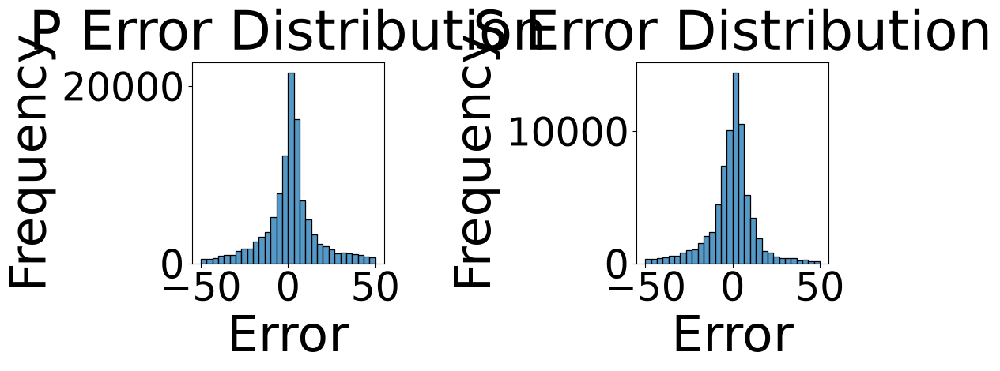

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_moe[result_moe['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_moe[result_moe['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# EQT

In [30]:

# stead=pd.read_csv('/home/cloudlab/意大利数据集instancegm/Instance.csv')
# phasenet=phasenet.loc[:90000]

In [31]:


# 提取 eqt 中的 file_name
file_names = eqt['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(eqt, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['trace_P_arrival_sample']/2 - merged['p_idx'])
merged['s_error'] = (merged['trace_S_arrival_sample']/2 - merged['s_idx'])


# 选择需要的列
result_eqt = merged[['trace_name', 'trace_P_arrival_sample','trace_S_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_eqt

,trace_name,trace_P_arrival_sample,trace_S_arrival_sample,p_idx,s_idx,p_error,s_error
0,"bucket1050$1019,:3,:12000",1700,NaN,848,1579.0,2.0,NaN
1,"bucket1002$29,:3,:12000",2034,2720.0,1010,1381.0,7.0,-21.0
2,"bucket747$92,:3,:12000",1705,NaN,837,NaN,15.5,NaN
3,"bucket17$423,:3,:12000",1798,2025.0,897,1031.0,2.0,-18.5
4,"bucket514$763,:3,:12000",2072,3718.0,1030,NaN,6.0,NaN
...,...,...,...,...,...,...,...
138250,"bucket483$699,:3,:12000",1793,3107.0,882,1557.0,14.5,-3.5
138251,"bucket538$246,:3,:12000",1676,NaN,851,1326.0,-13.0,NaN
138252,"bucket833$386,:3,:12000",1967,NaN,977,NaN,6.5,NaN
138253,"bucket320$834,:3,:12000",1967,2236.0,979,1119.0,4.5,-1.0


In [32]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 50
TP_threshold_FN= 50
result_eqt.loc[:, 'p_TP'] = np.where(abs(result_eqt['p_error']) <= TP_threshold_TP, 1, 0)
result_eqt.loc[:, 's_TP'] = np.where(abs(result_eqt['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_eqt.loc[:, 'p_FN'] = np.where(abs(result_eqt['p_error']) > TP_threshold_FN, 1, 0)
result_eqt.loc[:, 's_FN'] = np.where(abs(result_eqt['s_error']) > TP_threshold_FN, 1, 0)

# #FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
# result_moe.loc[:, 'p_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)
# result_moe.loc[:, 's_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)

#计算stead的随机种子样本的noise个数
sampled_data = stead.sample(frac=ration, random_state=random_set)
sampled_data_count=len(stead.sample(frac=ration, random_state=random_set))
# noise_count = len(sampled_data[sampled_data['trace_category'] == 'noise'])
earthquake_count=sampled_data_count

#FP：噪声误报 + 未检测到的地震事件（除开噪声）
# p_FP_count=earthquake_count - result_eqt.loc[:, 'p_TP'].sum() - result_eqt.loc[:, 'p_FN'].sum()
# s_FP_count=earthquake_count - result_eqt.loc[:, 's_TP'].sum() - result_eqt.loc[:, 's_FN'].sum()
p_FP_count=earthquake_count - result_eqt.loc[:, 'p_TP'].sum()
s_FP_count=earthquake_count - result_eqt.loc[:, 's_TP'].sum()



#计算precision，recall，f1
p_TP= result_eqt['p_TP'].sum()
s_TP= result_eqt['s_TP'].sum()

p_FN= result_eqt['p_FN'].sum()
s_FN= result_eqt['s_FN'].sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_eqt.loc[:, 'p_TP_mae'] = np.where(result_eqt['p_TP'] == 1, result_eqt['p_error'], 0)
result_eqt.loc[:, 's_TP_mae'] = np.where(result_eqt['s_TP'] == 1, result_eqt['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_eqt['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_eqt['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_eqt['p_TP_mae'].std() / 100
s_TP_std = result_eqt['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


result_table_eqt = pd.DataFrame({
    'EQT': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_eqt.loc[result_table_eqt['EQT'].isin(int_rows), ['P', 'S']] = (
    result_table_eqt.loc[result_table_eqt['EQT'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 105629
P-FP: 10296
P-FN: 32626
P-Precision: 0.9111839551434117
P-Recall: 0.7640157679649923
P-F1 Score: 0.8311354158470377
P-MAE: 0.08242532827159207
P-STD: 0.10088389240551196
S-TP: 68832
S-FP: 47093
S-FN: 4407
S-Precision: 0.5937632089713176
S-Recall: 0.9398271412771884
S-F1 Score: 0.7277494660717684
S-MAE: 0.09776310437006044
S-STD: 0.09078878766874998


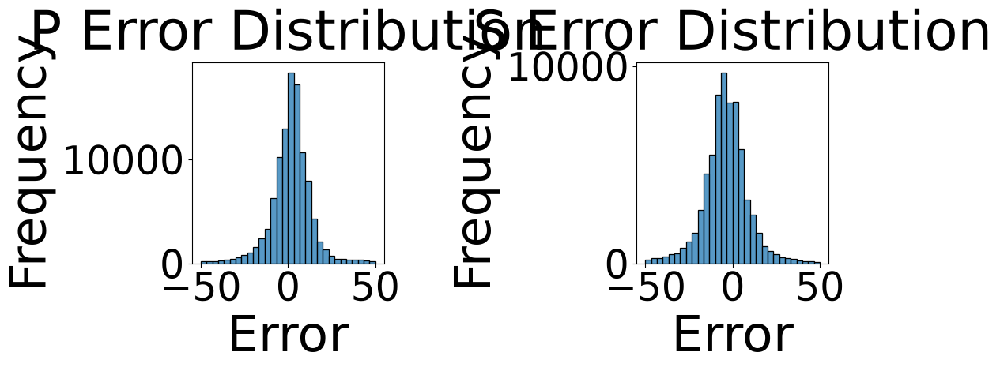

In [33]:


import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_eqt[result_eqt['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_eqt[result_eqt['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# PhaseNet

In [34]:

# phasenet=phasenet.loc[:90000]
# stead=pd.read_csv('/home/cloudlab/意大利数据集instancegm/Instance.csv')

In [35]:


# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['trace_P_arrival_sample']/2 - merged['p_idx'])
merged['s_error'] = (merged['trace_S_arrival_sample']/2 - merged['s_idx'])


# 选择需要的列
result_phasenet = merged[['trace_name', 'trace_P_arrival_sample','trace_S_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_phasenet

,trace_name,trace_P_arrival_sample,trace_S_arrival_sample,p_idx,s_idx,p_error,s_error
0,"bucket1050$1019,:3,:12000",1700,NaN,858,1579.0,-8.0,NaN
1,"bucket1002$29,:3,:12000",2034,2720.0,1019,1337.0,-2.0,23.0
2,"bucket747$92,:3,:12000",1705,NaN,848,2488.0,4.5,NaN
3,"bucket17$423,:3,:12000",1798,2025.0,899,1021.0,0.0,-8.5
4,"bucket514$763,:3,:12000",2072,3718.0,1033,1893.0,3.0,-34.0
...,...,...,...,...,...,...,...
120183,"bucket1050$593,:3,:12000",1995,NaN,1016,1695.0,-18.5,NaN
120184,"bucket251$875,:3,:12000",1887,3786.0,189,1950.0,754.5,-57.0
120185,"bucket593$270,:3,:12000",1841,NaN,1021,1798.0,-100.5,NaN
120186,"bucket130$45,:3,:12000",1789,2136.0,71,4004.0,823.5,-2936.0


In [36]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 50
TP_threshold_FN= 50
result_phasenet.loc[:, 'p_TP'] = np.where(abs(result_phasenet['p_error']) <= TP_threshold_TP, 1, 0)
result_phasenet.loc[:, 's_TP'] = np.where(abs(result_phasenet['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_phasenet.loc[:, 'p_FN'] = np.where(abs(result_phasenet['p_error']) > TP_threshold_FN, 1, 0)
result_phasenet.loc[:, 's_FN'] = np.where(abs(result_phasenet['s_error']) > TP_threshold_FN, 1, 0)

# #FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
# result_moe.loc[:, 'p_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)
# result_moe.loc[:, 's_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)

#计算stead的随机种子样本的noise个数
sampled_data = stead.sample(frac=ration, random_state=random_set)
sampled_data_count=len(stead.sample(frac=ration, random_state=random_set))
# noise_count = len(sampled_data[sampled_data['trace_category'] == 'noise'])
earthquake_count=sampled_data_count

#FP：噪声误报 + 未检测到的地震事件（除开噪声）
# p_FP_count=earthquake_count - result_phasenet.loc[:, 'p_TP'].sum() - result_phasenet.loc[:, 'p_FN'].sum()
# s_FP_count=earthquake_count - result_phasenet.loc[:, 's_TP'].sum() - result_phasenet.loc[:, 's_FN'].sum()
p_FP_count=earthquake_count - result_phasenet.loc[:, 'p_TP'].sum()
s_FP_count=earthquake_count - result_phasenet.loc[:, 's_TP'].sum()



#计算precision，recall，f1
p_TP= result_phasenet['p_TP'].sum()
s_TP= result_phasenet['s_TP'].sum()

p_FN= result_phasenet['p_FN'].sum()
s_FN= result_phasenet['s_FN'].sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_phasenet.loc[:, 'p_TP_mae'] = np.where(result_phasenet['p_TP'] == 1, result_phasenet['p_error'], 0)
result_phasenet.loc[:, 's_TP_mae'] = np.where(result_phasenet['s_TP'] == 1, result_phasenet['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_phasenet['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_phasenet['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_phasenet['p_TP_mae'].std() / 100
s_TP_std = result_phasenet['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


result_table_phasenet = pd.DataFrame({
    'PhaseNet': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})

# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_phasenet.loc[result_table_phasenet['PhaseNet'].isin(int_rows), ['P', 'S']] = (
    result_table_phasenet.loc[result_table_phasenet['PhaseNet'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 104206
P-FP: 11719
P-FN: 15982
P-Precision: 0.8989087772266552
P-Recall: 0.8670249941757913
P-F1 Score: 0.8826790562146092
P-MAE: 0.06987399957775944
P-STD: 0.0982073378148021
S-TP: 67360
S-FP: 48565
S-FN: 6980
S-Precision: 0.581065343972396
S-Recall: 0.906107075598601
S-F1 Score: 0.708065067143195
S-MAE: 0.09412982482185273
S-STD: 0.09570627945482571


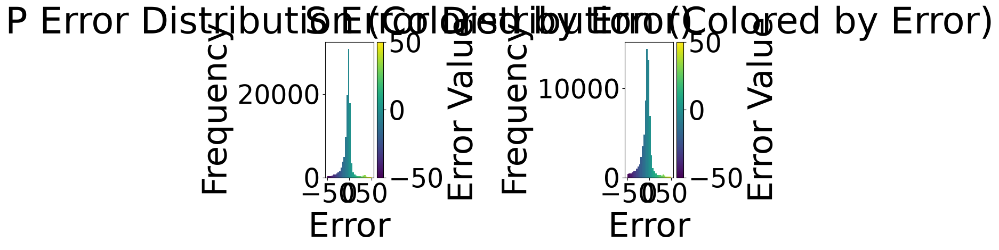

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize

plt.figure(figsize=(12, 6))

# ---------------------------
# P 误差分布（横坐标误差值映射到颜色）
# ---------------------------
plt.subplot(1, 2, 1)
p_data = result_phasenet[result_phasenet['p_TP'] == 1]['p_error']
counts, bins, patches = plt.hist(p_data, bins=30)

# 颜色映射：根据误差值（bins）设置颜色
norm = Normalize(vmin=bins.min(), vmax=bins.max())  # 颜色范围 = 误差范围
cmap = cm.viridis
for bin_val, patch in zip(bins[:-1], patches):  # bins[:-1] 是每个柱的左边界
    patch.set_facecolor(cmap(norm(bin_val)))

# 添加色标
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, label='Error Value', ax=plt.gca())  # ax=plt.gca() 指定当前子图
plt.title('P Error Distribution (Colored by Error)')
plt.xlabel('Error')
plt.ylabel('Frequency')

# ---------------------------
# S 误差分布（横坐标误差值映射到颜色）
# ---------------------------
plt.subplot(1, 2, 2)
s_data = result_phasenet[result_phasenet['s_TP'] == 1]['s_error']
counts, bins, patches = plt.hist(s_data, bins=30)

# 颜色映射
norm = Normalize(vmin=bins.min(), vmax=bins.max())
cmap = cm.viridis
for bin_val, patch in zip(bins[:-1], patches):
    patch.set_facecolor(cmap(norm(bin_val)))

# 添加色标
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, label='Error Value', ax=plt.gca())
plt.title('S Error Distribution (Colored by Error)')
plt.xlabel('Error')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# Results

In [38]:
import pandas as pd


# 2) Moe 表同理
df_moe = result_table_moe.set_index('Moe')
df_moe.columns = pd.MultiIndex.from_tuples([('Moe', col) for col in df_moe.columns])

# 1) 以 EQT 表举例
df_eqt = result_table_eqt.set_index('EQT')
# 将原本的列 ['P', 'S'] 改成多层索引：最上层 'EQT'，第二层保持原列名
df_eqt.columns = pd.MultiIndex.from_tuples([('EQT', col) for col in df_eqt.columns])


# 3) PhaseNet 表
df_phasenet = result_table_phasenet.set_index('PhaseNet')
df_phasenet.columns = pd.MultiIndex.from_tuples([('PhaseNet', col) for col in df_phasenet.columns])

# 4) 横向合并
df_multi = pd.concat([df_moe,df_eqt, df_phasenet], axis=1)

print('-----------------------------------Instance----------------------------------------------')
df_multi


-----------------------------------Instance----------------------------------------------


Moe                          EQT                \
                       P             S              P             S   
TP         108973.000000  72938.000000  105629.000000  68832.000000   
FP           6952.000000  42987.000000   10296.000000  47093.000000   
FN          13582.000000   4582.000000   32626.000000   4407.000000   
Precision       0.940030      0.629183       0.911184      0.593763   
Recall          0.889176      0.940893       0.764016      0.939827   
F1 Score        0.913896      0.754095       0.831135      0.727749   
MAE             0.106991      0.088567       0.082425      0.097763   
STD             0.147377      0.101749       0.100884      0.090789   

                PhaseNet                
                       P             S  
TP         104206.000000  67360.000000  
FP          11719.000000  48565.000000  
FN          15982.000000   6980.000000  
Precision       0.898909      0.581065  
Recall          0.867025      0.906107  
F1 Score        0.882679      0.708065  
MAE             0.069874      0.094130  
STD             0.098207      0.095706

| Instance<br/> | Moe<br/>P     | Moe<br/>S | EQT<br/>P | EQT<br/>S | PhaseNet<br/>P | PhaseNet<br/>S |
| :--- |:--------------| :--- | :--- | :--- | :--- | :--- |
| TP | 108973.000000 | 72938.000000 | 105629.000000 | 68832.000000 | 104206.000000 | 67360.000000 |
| FP | 6952.000000   | 42987.000000 | 10296.000000 | 47093.000000 | 11719.000000 | 48565.000000 |
| FN | 13582.000000  | 4582.000000 | 32626.000000 | 4407.000000 | 15982.000000 | 6980.000000 |
| Precision | 0.940030      | 0.629183 | 0.911184 | 0.593763 | 0.898909 | 0.581065 |
| Recall | 0.889176      | 0.940893 | 0.764016 | 0.939827 | 0.867025 | 0.906107 |
| F1 Score | 0.913896      | 0.754095 | 0.831135 | 0.727749 | 0.882679 | 0.708065 |
| MAE |      0.069874 | 0.088567 | 0.082425 | 0.097763 |0.106991  | 0.094130 |
| STD |    0.098207  | 0.101749 | 0.100884 | 0.090789 |0.147377   | 0.095706 |


# Figure

# EQT Figure

In [39]:
# 统一模型命名：按图例中的模型名定义 P/S 误差序列（数据、对应关系、MAE 均保持不变）
p_seismoe = result_phasenet[result_phasenet['p_TP'] == 1]['p_error'] / 100
p_eqt = result_eqt[result_eqt['p_TP'] == 1]['p_error'] / 100
p_phasenet = result_moe[result_moe['p_TP'] == 1]['p_error'] / 100
s_seismoe = result_moe[result_moe['s_TP'] == 1]['s_error'] / 100
s_eqt = result_eqt[result_eqt['s_TP'] == 1]['s_error'] / 100
s_phasenet = result_phasenet[result_phasenet['s_TP'] == 1]['s_error'] / 100


In [40]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
import matplotlib.colors as colors
import scienceplots
import os
from matplotlib.ticker import FuncFormatter


base_fontsize = 50

plt.rcParams.update({
    'font.size': base_fontsize,
    'axes.titlesize': base_fontsize * 1.0,
    'axes.labelsize': base_fontsize * 0.9,
    'xtick.labelsize': base_fontsize * 0.7,
    'ytick.labelsize': base_fontsize * 0.7,
    'legend.fontsize': base_fontsize * 0.8,
    'figure.titlesize': base_fontsize * 1.2
})

cmap_pos = plt.colormaps['viridis'].reversed()
cmap_neg = plt.colormaps['viridis']

def plot_error_distribution(data, title, xlabel, mae, sigma, store_path, filename):
    with plt.style.context(['science', 'ieee']):
        fig, ax = plt.subplots(figsize=(10, 6))
        counts, bins = np.histogram(data, bins=30)
        max_pos, min_neg = 0.5, -0.5
        norm_pos = colors.Normalize(vmin=0, vmax=max_pos)
        norm_neg = colors.Normalize(vmin=min_neg, vmax=0)

        for count, left, right in zip(counts, bins[:-1], bins[1:]):
            center = 0.5 * (left + right)
            color = cmap_pos(norm_pos(center)) if center >= 0 else cmap_neg(norm_neg(center))
            ax.bar(center, count, width=right - left, color=color, align='center')

        ax.set_title(title, pad=20)
        # ax.set_xlabel(xlabel, labelpad=15)
        ax.set_ylim(0, counts.max() * 1.1)
        ax.set_xticks([])

        # 设置 y 轴的显示格式
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y / 1e3:.1f}' if y < 1000 else f'{y / 1e3:.0f}'))

        # 在 y 轴顶部添加 ×10³
        ax.text(0, 1.01, r'$\times 10^3$',
                transform=ax.transAxes,
                fontsize=base_fontsize * 0.7,
                ha='left', va='bottom')

        # 添加统计信息文本框
        stats_text = f'$\\mathrm{{MAE}}={mae}\\,\\mathrm{{s}}$\n$\\sigma={sigma}\\,\\mathrm{{s}}$'
        ax.text(0.95, 0.95, stats_text,
                transform=ax.transAxes,
                ha='right', va='top',
                fontsize=base_fontsize * 0.6,
                bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=10))

        plt.tight_layout()
        path = os.path.join(store_path, filename)
        plt.savefig(path, dpi=600, bbox_inches='tight')
        plt.show()


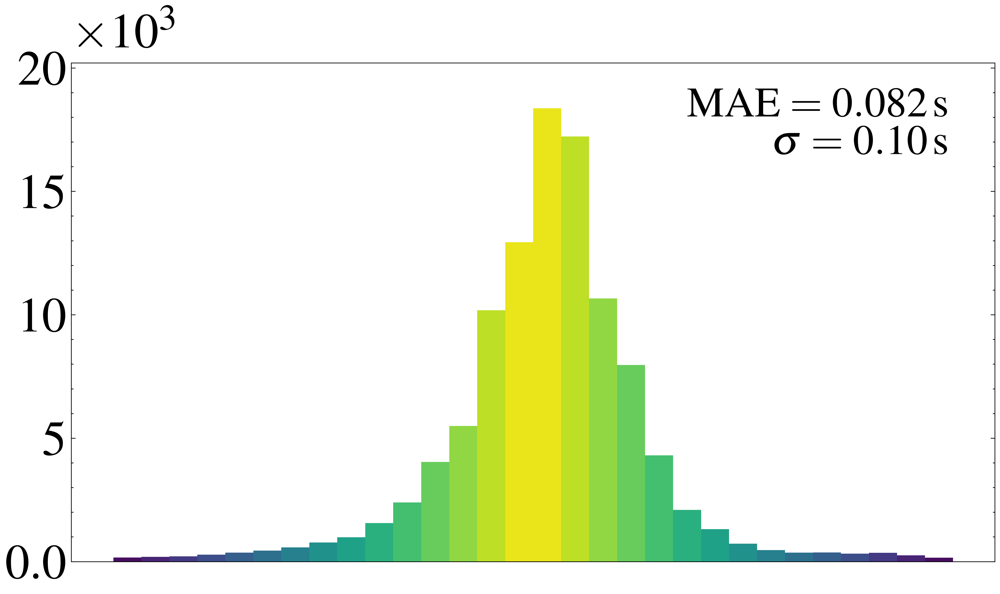

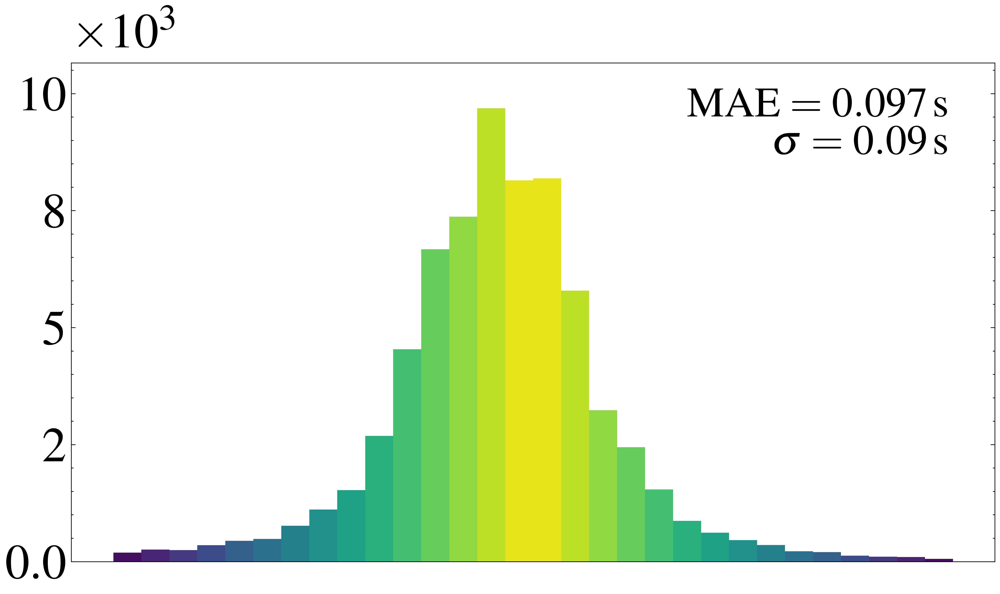

In [41]:

# 绘制P波
data_p = p_eqt
plot_error_distribution(data_p,
                      '',
                      'EQTransformer P Picking Error (s)',
                      '0.082', '0.10',
                      '/home/yuan/code/SeisMoE/results/disturb_photo/Instance_Predict',
                      'EQTransformer_P_error_distribution.svg')

# 绘制S波
data_s = s_eqt
plot_error_distribution(data_s,
                      '',
                      'EQTransformer S Picking Error (s)',
                      '0.097', '0.09',
                        '/home/yuan/code/SeisMoE/results/disturb_photo/Instance_Predict',
                      'EQTransformer_S_error_distribution.svg')

# Moe Figure

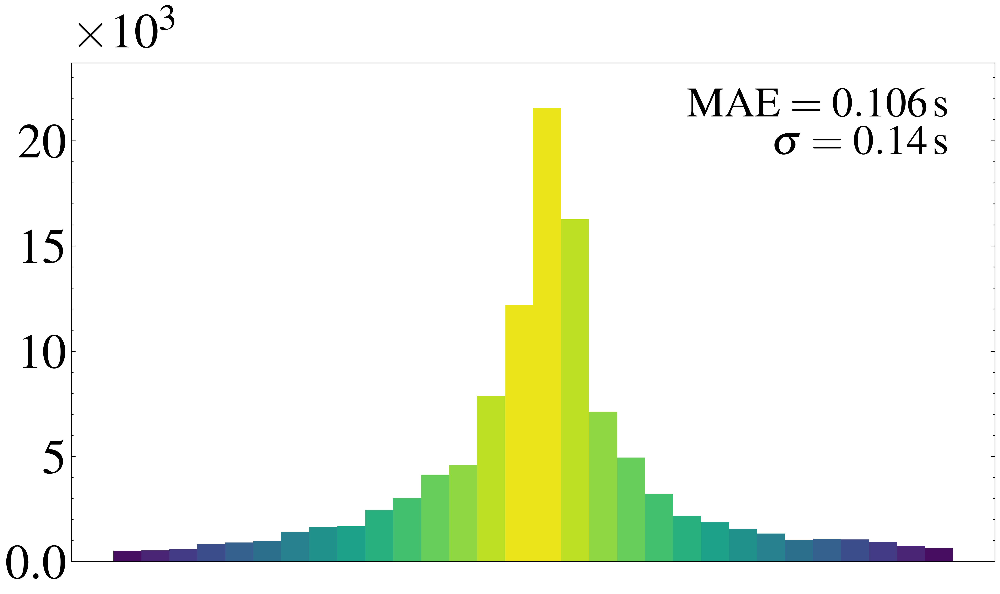

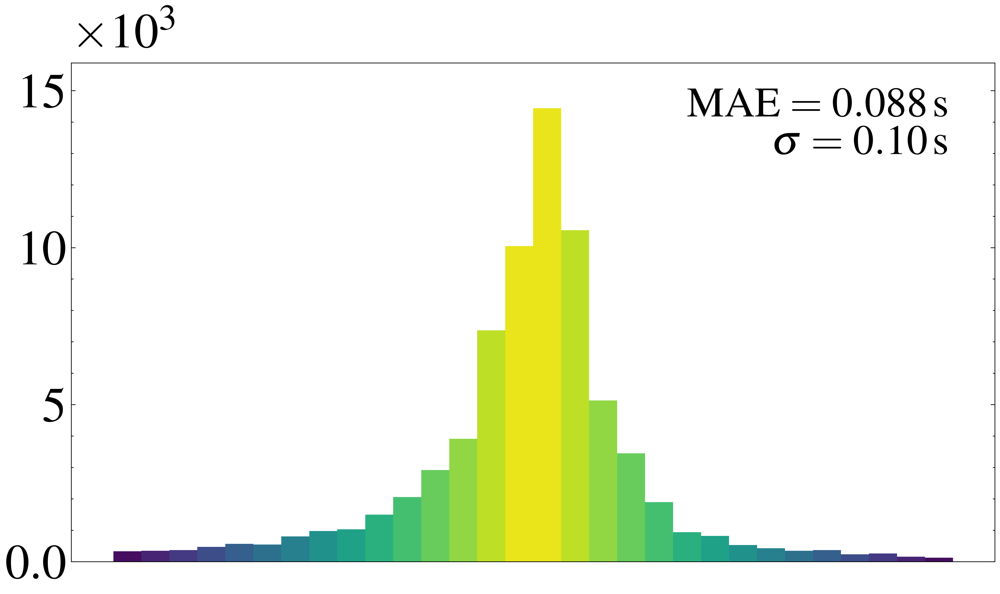

In [42]:

# 绘制P波
data_p = p_phasenet
plot_error_distribution(data_p,
                      '',
                      'PhaseNet P Picking Error (s)',
                      '0.106', '0.14',
                        '/home/yuan/code/SeisMoE/results/disturb_photo/Instance_Predict',
                      'PhaseNet_P_error_distribution.svg')

# 绘制S波
data_s = s_seismoe
plot_error_distribution(data_s,
                      '',
                      'SeisMoe S Picking Error (s)',
                      '0.088', '0.10',
                        '/home/yuan/code/SeisMoE/results/disturb_photo/Instance_Predict',
                      'SeisMoe_S_error_distribution.svg')

# PhaseNet Figure

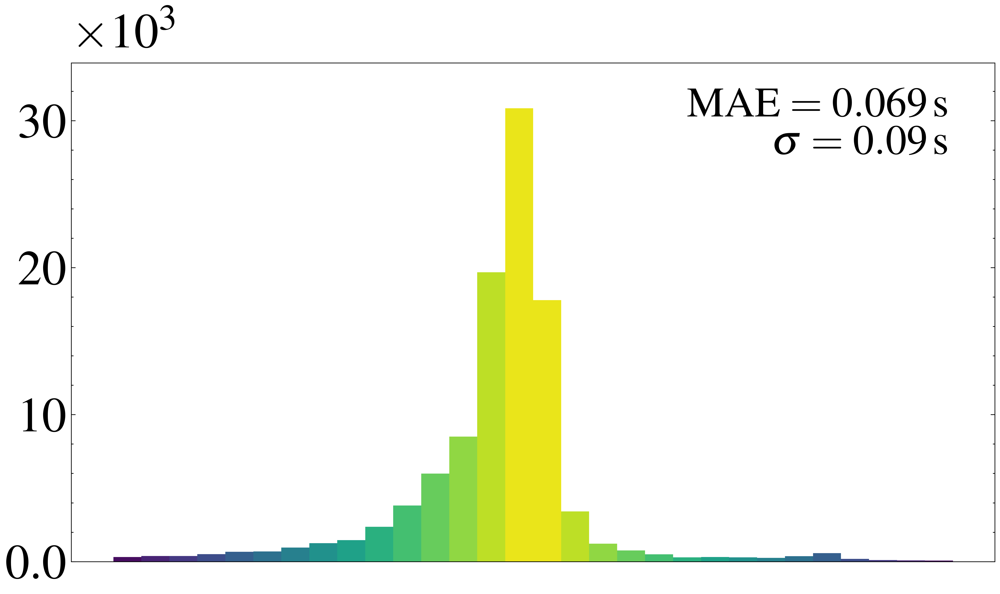

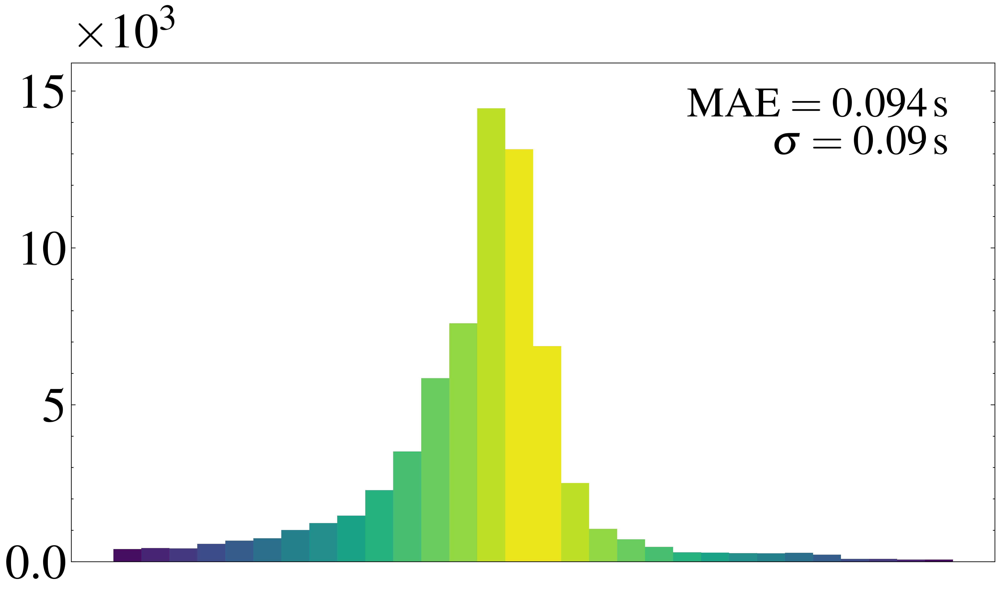

In [43]:

# 绘制P波
data_p = p_seismoe
plot_error_distribution(data_p,
                      '',
                      'SeisMoe P Picking Error (s)',
                      '0.069', '0.09',
                        '/home/yuan/code/SeisMoE/results/disturb_photo/Instance_Predict',
                      'SeisMoe_P_error_distribution.svg')

# 绘制S波
data_s = s_phasenet
plot_error_distribution(data_s,
                      '',
                      'PhaseNet S Picking Error (s)',
                      '0.094', '0.09',
                        '/home/yuan/code/SeisMoE/results/disturb_photo/Instance_Predict',
                      'PhaseNet_S_error_distribution.svg')

# ALL figure

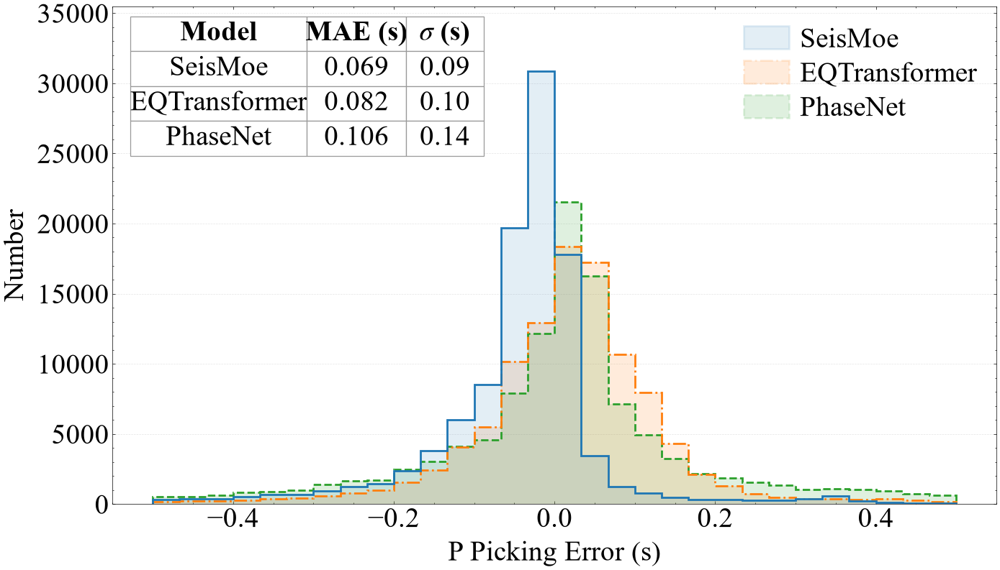

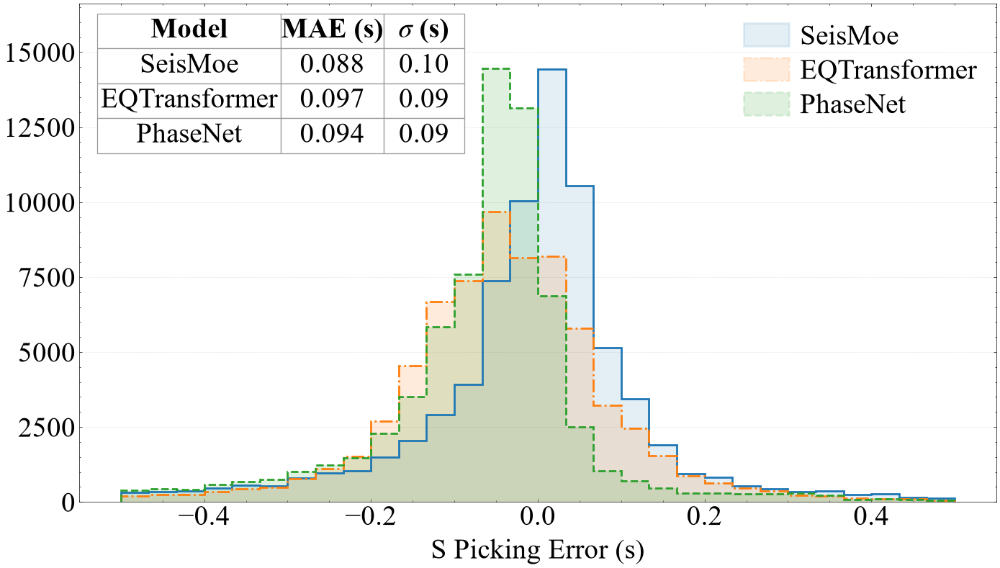

In [44]:
# ALL figure: 将 PhaseNet / EQTransformer / SeisMoe 的 P、S 误差分布叠加在同一坐标轴内
# 风格：scienceplots Nature + Times New Roman；空心阶梯轮廓线（无背景填充）
#      黑白友好：灰度 + 线型（实线/虚线/点划线）区分模型，下宽上窄排序避免遮挡

import matplotlib.font_manager as fm
from matplotlib.patches import Patch

base_fontsize = 28

# 注册 Times New Roman：WSL 下取 Windows 字体；缺失时由 rcParams 回退到 Nimbus Roman 等
for _fp in ['/mnt/c/Windows/Fonts/times.ttf', '/mnt/c/Windows/Fonts/timesbd.ttf',
            '/mnt/c/Windows/Fonts/timesi.ttf', '/mnt/c/Windows/Fonts/timesbi.ttf']:
    if os.path.exists(_fp):
        fm.fontManager.addfont(_fp)

model_colors = {
    'SeisMoe': '#1f77b4',
    'EQTransformer': '#ff7f0e',
    'PhaseNet': '#2ca02c',
}

# 每个模型固定线型/线宽，保证黑白打印时也能区分（不随图层顺序变化）
# SeisMoe 作为主模型：最粗黑色实线，最突出
model_line_styles = {
    'PhaseNet': ('--', 2.0),
    'EQTransformer': ('-.', 2.0),
    'SeisMoe': ('-', 2.0),
}

model_fill_alpha = {
    'PhaseNet': 0.15,
    'EQTransformer': 0.15,
    'SeisMoe': 0.12,
}

# 表格与图例的固定显示顺序：SeisMoe 第一，EQTransformer 第二，PhaseNet 第三
display_order = ['SeisMoe', 'EQTransformer', 'PhaseNet']


def plot_overlay_error_distribution(series, title, store_path, filename, bins=30, xlabel='', ylabel=''):
    # series 每一项为 (label, data, color, mae, sigma)
    with plt.style.context(['science', 'nature']):
        # 字体统一使用 Times New Roman；关闭 usetex 以免回退到 Computer Modern
        plt.rcParams['text.usetex'] = False
        plt.rcParams['font.family'] = 'serif'
        plt.rcParams['font.serif'] = ['Times New Roman', 'Nimbus Roman', 'Liberation Serif', 'FreeSerif', 'DejaVu Serif']
        plt.rcParams['mathtext.fontset'] = 'stix'
        fig, ax = plt.subplots(figsize=(14, 8))

        all_data = np.concatenate([np.asarray(item[1], dtype=float) for item in series])
        edges = np.linspace(all_data.min(), all_data.max(), bins + 1)

        # 按分布宽度从大到小排序：宽分布在下、窄分布在上，避免窄分布被遮住
        layers = sorted(series, key=lambda it: float(np.std(np.asarray(it[1], dtype=float))), reverse=True)

        max_count = 0
        for i, (label, data, color, _, _) in enumerate(layers):
            values = np.asarray(data, dtype=float)
            counts, _ = np.histogram(values, bins=edges)
            max_count = max(max_count, int(counts.max()))
            ls, lw = model_line_styles[label]

            ax.hist(values, bins=edges, histtype='stepfilled', color=color, alpha=model_fill_alpha[label], edgecolor='none', zorder=2 + i)
            ax.hist(values, bins=edges, histtype='step', color=color,
                    linewidth=lw, linestyle=ls, zorder=10 + i, label=label)

        ax.set_title(title, pad=18)
        ax.set_ylim(0, max_count * 1.15)
        if xlabel:
            ax.set_xlabel(xlabel, labelpad=8, fontsize=28)
        if ylabel:
            ax.set_ylabel(ylabel, labelpad=8, fontsize=28)
        # ax.axvline(0, color='0.6', linestyle='--', linewidth=1.0, zorder=1)
        ax.grid(axis='y', color='0.85', linestyle='--', linewidth=0.5, alpha=0.7)
        ax.set_axisbelow(True)

        ax.tick_params(axis='both', which='major', labelsize=28)
        ax.ticklabel_format(axis='y', style='plain', useOffset=False)

        # 图例按 SeisMoe / EQTransformer / PhaseNet 固定顺序排列，与表格一致
        legend_handles = []
        
        for label in display_order:
            if any(label == s[0] for s in series):
                ls, lw = model_line_styles[label]
                legend_handles.append(Patch(facecolor=model_colors[label], edgecolor=model_colors[label], alpha=model_fill_alpha[label], linewidth=lw, linestyle=ls, label=label))

        ax.legend(handles=legend_handles, loc='upper right', frameon=False,
                fontsize=base_fontsize,
                handlelength=1.6, handleheight=0.9,
                handletextpad=0.4, labelspacing=0.25,
                borderaxespad=0.3)

        # 统计信息表格：使用上方单独绘图中写明的 MAE 与 sigma
        col_labels = ['Model', 'MAE (s)', r'$\sigma$ (s)']
        by_label = {label: [label, mae, sigma] for label, _, _, mae, sigma in series}
        cell_text = [by_label[l] for l in display_order if l in by_label]
        table = ax.table(cellText=cell_text, colLabels=col_labels,
                         cellLoc='center', colLoc='center',
                         colWidths=[0.50, 0.28, 0.22],
                         loc='upper left', bbox=[0.02, 0.70, 0.40, 0.28])
        table.set_zorder(5)
        table.auto_set_font_size(False)
        table.set_fontsize(base_fontsize)
        for (row, col), cell in table.get_celld().items():
            cell.set_facecolor((1, 1, 1, 0.88))
            cell.set_edgecolor('0.6')
            cell.set_linewidth(0.9)
            cell.PAD = 0.04
            if row == 0:
                cell.set_text_props(fontweight='bold', color='black')
            else:
                cell.set_text_props(color='black')

        plt.tight_layout()
        plt.savefig(os.path.join(store_path, filename), dpi=600, bbox_inches='tight')
        plt.show()


all_store_path = '/home/yuan/code/SeisMoE/results/disturb_photo/Instance_Predict'

# P 波叠加图（MAE/sigma 取自上面对应 Figure 中写明的数值）
p_series = [
    ('EQTransformer', p_eqt, model_colors['EQTransformer'], '0.082', '0.10'),
    ('PhaseNet', p_phasenet, model_colors['PhaseNet'], '0.106', '0.14'),
    ('SeisMoe', p_seismoe, model_colors['SeisMoe'], '0.069', '0.09'),
]
plot_overlay_error_distribution(p_series, '', all_store_path, 'ALL_P_error_distribution.svg', xlabel='P Picking Error (s)', ylabel='Number')

# S 波叠加图（MAE/sigma 取自上面对应 Figure 中写明的数值）
s_series = [
    ('EQTransformer', s_eqt, model_colors['EQTransformer'], '0.097', '0.09'),
    ('SeisMoe', s_seismoe, model_colors['SeisMoe'], '0.088', '0.10'),
    ('PhaseNet', s_phasenet, model_colors['PhaseNet'], '0.094', '0.09'),
]
plot_overlay_error_distribution(s_series, '', all_store_path, 'ALL_S_error_distribution.svg', xlabel='S Picking Error (s)')


# Instance Samples Figure

## Moe predict

In [23]:




#!/usr/bin/env python
# -*- coding: utf-8 -*-
def Moe_predict(trace_name):
    import os
    import random
    import sys
    import h5py
    import numpy as np
    import pandas as pd
    import torch
    from scipy.signal import find_peaks
    from torch.utils.data import Dataset, DataLoader
    from tqdm import tqdm
    from datetime import datetime, timedelta
    import multiprocessing as mp
    from scipy.signal import resample,butter,filtfilt
    import os
    os.environ["CUDA_VISIBLE_DEVICES"]="1"
    # 将自定义模型文件所在目录加入路径
    sys.path.append("/home/yuan/code/SeisMoE/src")
    # 导入自定义模型文件，假设其中包含与 seisbench EQTransformer 接口相同的模型类
    from model_moe_gpt_PS2_CPU import IMG1

    def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
        """使用 scipy.signal.find_peaks 实现相位检测"""
        p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
        s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

        best_p = p_peaks[p_props['peak_heights'].argmax()] if len(p_peaks) > 0 else None
        best_s = None

        if best_p is not None:
            for s in s_peaks:
                if 0 < (s - best_p) < 6000:  # 60秒窗口(100Hz采样)
                    best_s = s
                    break

        return best_p, best_s, p_props['peak_heights'].max() if best_p is not None else None, \
            s_props['peak_heights'][s_peaks.tolist().index(best_s)] if best_s is not None else None




    def normalize_data1(data, mode='std'):
        data -= np.mean(data, axis=1, keepdims=True)

        if mode == 'std':
            std_val = np.std(data, axis=1, keepdims=True)
            std_val[std_val == 0] = 1.0
            data /= std_val
        elif mode == 'max':
            max_val = np.max(np.abs(data), axis=1, keepdims=True)
            max_val[max_val == 0] = 1.0
            data /= max_val
        else:
            raise ValueError(f"Unsupported norm_mode: {mode}")
        return data

    def normalize_data2(data, mode='max'):
        data -= np.mean(data, axis=0, keepdims=True)
        if mode == 'max':
            max_data = np.max(data, axis=0, keepdims=True)
            assert (max_data.shape[-1] == data.shape[-1])
            max_data[max_data == 0] = 1
            data /= max_data

        elif mode == 'std':
            std_data = np.std(data, axis=0, keepdims=True)
            assert (std_data.shape[-1] == data.shape[-1])
            std_data[std_data == 0] = 1
            data /= std_data
        return data

    def bandpass_filter(data, lowcut, highcut, fs, order=4):
        """
        对每个通道数据进行带通滤波。
        data: 形状为 (3, T)
        lowcut, highcut: 滤波器截止频率
        fs: 采样率
        """
        nyquist = 0.5 * fs
        low = lowcut / nyquist
        high = highcut / nyquist
        b, a = butter(order, [low, high], btype='band')

        filtered = np.zeros_like(data)
        for ch in range(data.shape[0]):
            filtered[ch] = filtfilt(b, a, data[ch])
        return filtered

    def model_predict(model, data: torch.Tensor):
        with torch.no_grad():
            return model(data)




    hdf5_path="/home/cloudlab/意大利数据集instancegm/Instance.hdf5"
    p_thresh=0.1,
    s_thresh=0.1
    trace_names = trace_name



    trace_name =trace_names

    group = trace_name.split('$')[0].strip()
    index = int(trace_name.split('$')[1].split(',')[0].strip())
    f=h5py.File(hdf5_path,'r')
    dataset = f['data'].get(group)
    raw_data = dataset[index, :, :].astype(np.float32)  # shape: (3, n_samples)
    target_length=6000
    # 重采样到 target_length
    if raw_data.shape[1] != target_length:
        normalized = np.zeros((3, target_length), dtype=np.float32)
        for ch in range(3):
            normalized[ch] = resample(raw_data[ch], target_length)
    else:
        normalized = raw_data.astype(np.float32)

    # 滤波：1-45Hz 带通滤波
    normalized = bandpass_filter(normalized, lowcut=1.0, highcut=45.0, fs=100.0)

    # 标准化
    normalized = normalize_data1(normalized, mode='std')
    data=torch.from_numpy(normalized.T)
    data=data.unsqueeze(0)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # 加载自定义模型
    # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
    model = IMG1().to(device)
    model.load_state_dict(torch.load("/home/yuan/code/SeisMoE/models/Model_Store/CPU2_moe/best_model.pth",map_location=device))

    model.eval()

    results = []
    data = data.to(device)
    # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
    # 其中 output[1] 为 P 概率，output[2] 为 S 概率
    output,_ = model_predict(model, data)
    moe_p_prob= output[0].cpu()
    moe_s_prob= output[1].cpu()

    for i, (p_arr, s_arr) in enumerate(zip(moe_p_prob, moe_s_prob)):
        p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
        if p_idx is not None or s_idx is not None:
            results.append((i, p_idx, s_idx, p_conf, s_conf))

    # output_csv = os.path.join(output_dir, 'picks——moe2.csv')
    results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])

    moe_p=results['p_idx'].values[0]
    moe_s=results['s_idx'].values[0]
    moe_pc=results['p_conf'].values[0]
    moe_sc=results['s_conf'].values[0]


    print(f"Moe P index:{results['p_idx'].values[0]}")
    print(f"Moe S index:{results['s_idx'].values[0]}")
    print(f"Moe P confidence:{results['p_conf'].values[0]}")
    print(f"Moe S confidence:{results['s_conf'].values[0]}")

    return moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob





## EQT Predict

In [24]:
    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def EQT_Predict(trace_name):
        import os
        import random
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        import seisbench.models as sbm
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        import h5py
        import numpy as np
        import torch
        from torch.utils.data import Dataset
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="2"
        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测，
            逻辑：仅根据 p_arr 中幅值最高的峰确定 P，
            然后在 P 后面 6000 个采样点内，从 s_arr 中选择幅值最高的峰作为 S。
            """
            # 对 p_arr 和 s_arr 分别进行峰值检测
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            # 选择 p_arr 中最高的峰作为 P
            if len(p_peaks) > 0:
                best_p_index = np.argmax(p_props['peak_heights'])
                best_p = p_peaks[best_p_index]
                p_conf = p_props['peak_heights'][best_p_index]
            else:
                best_p = None
                p_conf = None

            best_s = None
            s_conf = None

            if best_p is not None:
                # 筛选出在 P 后且距离 P 小于 6000 个采样点的所有 S 峰
                valid_s_indices = [i for i, s in enumerate(s_peaks) if s > best_p and (s - best_p) < 6000]
                if valid_s_indices:
                    valid_s_peaks = s_peaks[valid_s_indices]
                    valid_s_props = s_props['peak_heights'][valid_s_indices]
                    best_s_idx = np.argmax(valid_s_props)
                    best_s = valid_s_peaks[best_s_idx]
                    s_conf = valid_s_props[best_s_idx]
            return best_p, best_s, p_conf, s_conf


        def normalize_data1(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data

        def normalize_data2(data, mode='max'):
            data -= np.mean(data, axis=0, keepdims=True)
            if mode == 'max':
                max_data = np.max(data, axis=0, keepdims=True)
                assert (max_data.shape[-1] == data.shape[-1])
                max_data[max_data == 0] = 1
                data /= max_data

            elif mode == 'std':
                std_data = np.std(data, axis=0, keepdims=True)
                assert (std_data.shape[-1] == data.shape[-1])
                std_data[std_data == 0] = 1
                data /= std_data
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)

        # def main(trace_name, hdf5_path, p_thresh=0.3, s_thresh=0.3, batch_size=2048):



        hdf5_path=r'/home/cloudlab/意大利数据集instancegm/Instance.hdf5'
        p_thresh=0.1
        s_thresh=0.1
        trace_names = trace_name



        trace_name =trace_names

        group = trace_name.split('$')[0].strip()
        index = int(trace_name.split('$')[1].split(',')[0].strip())
        f=h5py.File(hdf5_path,'r')
        dataset = f['data'].get(group)
        raw_data = dataset[index, :, :].astype(np.float32)  # shape: (3, n_samples)
        target_length=6000
        # 重采样到 target_length
        if raw_data.shape[1] != target_length:
            normalized = np.zeros((3, target_length), dtype=np.float32)
            for ch in range(3):
                normalized[ch] = resample(raw_data[ch], target_length)
        else:
            normalized = raw_data.astype(np.float32)

        # 滤波：1-45Hz 带通滤波
        normalized = bandpass_filter(normalized, lowcut=1.0, highcut=45.0, fs=100.0)

        # 标准化
        normalized = normalize_data1(normalized, mode='std')
        data=torch.from_numpy(normalized)
        data=data.unsqueeze(0)

        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = sbm.EQTransformer.from_pretrained("original").to(device).eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output= model_predict(model, data)
        eqt_p_prob= output[1].cpu()
        eqt_s_prob= output[2].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(eqt_p_prob, eqt_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))


        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])
        eqt_p=results['p_idx'].values[0]
        eqt_s=results['s_idx'].values[0]
        eqt_pc=results['p_conf'].values[0]
        eqt_sc=results['s_conf'].values[0]
        # print(f"****拾取到的事件数：{len(results)}")
        print(f"eqt P index:{results['p_idx'].values[0]}")
        print(f"eqt S index:{results['s_idx'].values[0]}")
        print(f"eqt P confidence:{results['p_conf'].values[0]}")
        print(f"eqt S confidence:{results['s_conf'].values[0]}")

        return eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob


## PhaseNet Predict

In [25]:
    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def PhaseNet_predict(trace_name):
        import os
        import random
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        import seisbench.models as sbm
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        import h5py
        import numpy as np
        import torch
        from torch.utils.data import Dataset
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="2"
        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测，
            逻辑：仅根据 p_arr 中幅值最高的峰确定 P，
            然后在 P 后面 6000 个采样点内，从 s_arr 中选择幅值最高的峰作为 S。
            """
            # 对 p_arr 和 s_arr 分别进行峰值检测
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            # 选择 p_arr 中最高的峰作为 P
            if len(p_peaks) > 0:
                best_p_index = np.argmax(p_props['peak_heights'])
                best_p = p_peaks[best_p_index]
                p_conf = p_props['peak_heights'][best_p_index]
            else:
                best_p = None
                p_conf = None

            best_s = None
            s_conf = None

            if best_p is not None:
                # 筛选出在 P 后且距离 P 小于 6000 个采样点的所有 S 峰
                valid_s_indices = [i for i, s in enumerate(s_peaks) if s > best_p and (s - best_p) < 6000]
                if valid_s_indices:
                    valid_s_peaks = s_peaks[valid_s_indices]
                    valid_s_props = s_props['peak_heights'][valid_s_indices]
                    best_s_idx = np.argmax(valid_s_props)
                    best_s = valid_s_peaks[best_s_idx]
                    s_conf = valid_s_props[best_s_idx]
            return best_p, best_s, p_conf, s_conf


        def normalize_data1(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data

        def normalize_data2(data, mode='max'):
            data -= np.mean(data, axis=0, keepdims=True)
            if mode == 'max':
                max_data = np.max(data, axis=0, keepdims=True)
                assert (max_data.shape[-1] == data.shape[-1])
                max_data[max_data == 0] = 1
                data /= max_data

            elif mode == 'std':
                std_data = np.std(data, axis=0, keepdims=True)
                assert (std_data.shape[-1] == data.shape[-1])
                std_data[std_data == 0] = 1
                data /= std_data
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)

        # def main(trace_name, hdf5_path, p_thresh=0.3, s_thresh=0.3, batch_size=2048):



        hdf5_path=r'/home/cloudlab/意大利数据集instancegm/Instance.hdf5'
        p_thresh=0.1
        s_thresh=0.1
        trace_names = trace_name



        trace_name =trace_names

        group = trace_name.split('$')[0].strip()
        index = int(trace_name.split('$')[1].split(',')[0].strip())
        f=h5py.File(hdf5_path,'r')
        dataset = f['data'].get(group)
        raw_data = dataset[index, :, :].astype(np.float32)  # shape: (3, n_samples)
        target_length=6000
        # 重采样到 target_length
        if raw_data.shape[1] != target_length:
            normalized = np.zeros((3, target_length), dtype=np.float32)
            for ch in range(3):
                normalized[ch] = resample(raw_data[ch], target_length)
        else:
            normalized = raw_data.astype(np.float32)

        # 滤波：1-45Hz 带通滤波
        normalized = bandpass_filter(normalized, lowcut=1.0, highcut=45.0, fs=100.0)

        # 标准化
        normalized = normalize_data1(normalized, mode='std')
        data=torch.from_numpy(normalized)
        data=data.unsqueeze(0)

        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = sbm.PhaseNet.from_pretrained("original").to(device).eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output= model_predict(model, data)
        phasenet_p_prob= output[:,1,:].cpu()
        phasenet_s_prob= output[:,2,:].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(phasenet_p_prob, phasenet_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))


        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])
        phasenet_p=results['p_idx'].values[0]
        phasenet_s=results['s_idx'].values[0]
        phasenet_pc=results['p_conf'].values[0]
        phasenet_sc=results['s_conf'].values[0]
        # print(f"****拾取到的事件数：{len(results)}")
        print(f"phasenet P index:{results['p_idx'].values[0]}")
        print(f"phasenet S index:{results['s_idx'].values[0]}")
        print(f"phasenet P confidence:{results['p_conf'].values[0]}")
        print(f"phasenet S confidence:{results['s_conf'].values[0]}")

        return phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob


## sigale figure

In [26]:
cs=r'/home/cloudlab/意大利数据集instancegm/Instance.csv'
csv_data=pd.read_csv(cs)

FileNotFoundError: [Errno 2] No such file or directory: '/home/cloudlab/意大利数据集instancegm/Instance.csv'

In [ ]:
from scipy.signal import resample,butter,filtfilt
def Example_Figure(trace_name,
                   moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
                   eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
                   phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
                   Pquen1=50,
                   Pquen2=50,
                   Squen1=100,
                   Squen2=100,
                   store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Instance',
                   store_name='trace_name'):
    cs=r'/home/cloudlab/意大利数据集instancegm/Instance.csv'
    csv_data=pd.read_csv(cs)
    Psample=csv_data[csv_data['trace_name']==trace_name]['trace_P_arrival_sample'].values[0]/2
    Ssample=csv_data[csv_data['trace_name']==trace_name]['trace_S_arrival_sample'].values[0]/2
    print(f"Psample:{Psample}")
    print(f"Ssample:{Ssample}")
    import scienceplots
    import matplotlib.pyplot as plt
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes
    from matplotlib.patches import ConnectionPatch
    import h5py

    Pquen1=Pquen1
    Pquen2=Pquen2
    Squen1=Squen1
    Squen2=Squen2
    base_fontsize = 24  # 只需修改这个值即可全局调整

    plt.rcParams.update({
        'font.size': base_fontsize,
        'axes.titlesize': base_fontsize * 1.0,    # 标题=基准大小
        'axes.labelsize': base_fontsize * 0.9,    # 坐标轴标签=90%
        'xtick.labelsize': base_fontsize * 0.7,   # 刻度标签=70%
        'ytick.labelsize': base_fontsize * 0.7,
        'legend.fontsize': base_fontsize * 0.6,   # 图例=80%
        'figure.titlesize': base_fontsize * 1.2   # 图形标题=120%
    })


    try:
        phasenet_p_prob=np.squeeze(phasenet_p_prob.numpy())
        phasenet_s_prob=np.squeeze(phasenet_s_prob.numpy())
        eqt_p_prob=np.squeeze(eqt_p_prob.numpy())
        eqt_s_prob=np.squeeze(eqt_s_prob.numpy())
        moe_p_prob=np.squeeze(moe_p_prob.numpy())
        moe_s_prob=np.squeeze(moe_s_prob.numpy())
    except:
        pass

    def normalize_data1(data, mode='std'):
        data -= np.mean(data, axis=1, keepdims=True)

        if mode == 'std':
            std_val = np.std(data, axis=1, keepdims=True)
            std_val[std_val == 0] = 1.0
            data /= std_val
        elif mode == 'max':
            max_val = np.max(np.abs(data), axis=1, keepdims=True)
            max_val[max_val == 0] = 1.0
            data /= max_val
        else:
            raise ValueError(f"Unsupported norm_mode: {mode}")
        return data

    def normalize_data2(data, mode='max'):
        data -= np.mean(data, axis=0, keepdims=True)
        if mode == 'max':
            max_data = np.max(data, axis=0, keepdims=True)
            assert (max_data.shape[-1] == data.shape[-1])
            max_data[max_data == 0] = 1
            data /= max_data

        elif mode == 'std':
            std_data = np.std(data, axis=0, keepdims=True)
            assert (std_data.shape[-1] == data.shape[-1])
            std_data[std_data == 0] = 1
            data /= std_data
        return data

    def bandpass_filter(data, lowcut, highcut, fs, order=4):
        """
        对每个通道数据进行带通滤波。
        data: 形状为 (3, T)
        lowcut, highcut: 滤波器截止频率
        fs: 采样率
        """
        nyquist = 0.5 * fs
        low = lowcut / nyquist
        high = highcut / nyquist
        b, a = butter(order, [low, high], btype='band')

        filtered = np.zeros_like(data)
        for ch in range(data.shape[0]):
            filtered[ch] = filtfilt(b, a, data[ch])
        return filtered

    # GDXB.NC_20150501225411_EV
    hd=r'/home/cloudlab/意大利数据集instancegm/Instance.hdf5'
    ID=trace_name


    group = ID.split('$')[0].strip()
    index = int(ID.split('$')[1].split(',')[0].strip())
    f=h5py.File(hd,'r')
    dataset = f['data'].get(group)
    raw_data = dataset[index, :, :].astype(np.float32)  # shape: (3, n_samples)
    target_length=6000
    # 重采样到 target_length
    if raw_data.shape[1] != target_length:
        data = np.zeros((3, target_length), dtype=np.float32)
        for ch in range(3):
            data[ch] = resample(raw_data[ch], target_length)
    else:
        data = raw_data.astype(np.float32)

    
    data = bandpass_filter(data, lowcut=1.0, highcut=45.0, fs=100)
    data = normalize_data1(data, 'std').T
        

    # 创建 4 行 1 列的子图
    with plt.style.context(['science','ieee']):
        fig, axs = plt.subplots(4, 1, figsize=(16,10))

        # 绘制三分量数据
        axs[0].plot(data[:,2],color='k',label='Z',linewidth=0.3)
        # axs[0].set_title(f"2015-05-01 22:54:11,M=0.56,SNR=22.5")
        axs[0].axvline(x=Psample, color='#329845', linestyle='-.', label='Manual Pick',linewidth=0.3)
        axs[0].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=0.3)
        axs[0].axvline(x=phasenet_p, color='#F3C846', linestyle='--', label='PhaseNet Pick',linewidth=0.3) #  phasenet
        axs[0].axvline(x=phasenet_s, color='#F3C846', linestyle='--',linewidth=0.3) # phasenet
        axs[0].axvline(x=eqt_p, color='#53ABD8',linestyle=':', label='EQT Pick',linewidth=0.3) #  EQT
        axs[0].axvline(x=eqt_s, color='#53ABD8', linestyle='--',linewidth=0.3) # EQT
        axs[0].axvline(x=moe_s, color='#8A233F', linestyle='--', label='SeisMoe Pick',linewidth=0.3) #  SWEWT
        axs[0].axvline(x=moe_s, color='#8A233F', linestyle='--',linewidth=0.3) # SWEWT
        axs[0].legend(loc='upper right', frameon=True)
        axs[0].set_ylabel('Amplitude')
        # axs[0].set_xlabel('Sample')
        axs[0].set_xlim(0,6000)


        # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[0].get_position()

        # 计算左端对齐的位置
        axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
                            bbox_to_anchor=(pos.x0, 0.75, 0.3, 0.3),  # pos.x0 使左端对齐
                            bbox_transform=fig.transFigure)

        axins1.plot(data[:, 2], color='k',linewidth=0.3)
        x_position=Psample-Pquen1
        y_position=Psample+Pquen2

        axins1.set_xlim(x_position, y_position)  # 放大区域 x 轴范围

        axins1.axvline(x=Psample, color='#329845', linestyle='-.',linewidth=0.3) #  manual
        axins1.axvline(x=phasenet_p, color='#F3C846', linestyle='--',linewidth=0.3) #  phasenet
        axins1.axvline(x=eqt_p, color='#53ABD8',linestyle=':',linewidth=0.3) #  EQT
        axins1.axvline(x=moe_p, color='#8A233F', linestyle='--',linewidth=0.3) #  SWEWT


        # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), Pquen2+Pquen1, axs[0].get_ylim()[1] - axs[0].get_ylim()[0],
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        ## 连接主图和第一个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
        con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins1, color="k", linestyle="--",linewidth=0.3)
        con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins1, color="k", linestyle="--",linewidth=0.3)
        axs[0].add_artist(con1)
        axs[0].add_artist(con2)



       # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[0].get_position()

        # 计算右对齐的位置
        axins2 = inset_axes(axs[0], width="100%", height="40%", loc='upper right',
                            bbox_to_anchor=(pos.x1 - 0.3, 0.75, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                            bbox_transform=fig.transFigure)

        axins2.plot(data[:, 2], color='k',linewidth=0.3)
        x_position=Ssample-Squen1
        y_position=Ssample+Squen2
        axins2.set_xlim(x_position, y_position)  # 放大区域 x 轴范围


        # 在局部图中添加标记
        axins2.axvline(x=Ssample, color='#329845', linestyle='-.',linewidth=0.3) #manul
        axins2.axvline(x=phasenet_s, color='#F3C846', linestyle='--',linewidth=0.3) #phasenet
        axins2.axvline(x=eqt_s, color='#53ABD8',linestyle=':',linewidth=0.3) #EQT
        axins2.axvline(x=moe_s, color='#8A233F', linestyle='--',linewidth=0.3) #SWEWT

        # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), Squen2+Squen1, axs[0].get_ylim()[1] - axs[0].get_ylim()[0],
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        # 连接主图和第二个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
        con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins2, color="k", linestyle="--",linewidth=0.3)
        con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins2, color="k", linestyle="--",linewidth=0.3)
        axs[0].add_artist(con3)
        axs[0].add_artist(con4)


        axs[1].plot(data[:,1],color='k',label='N',linewidth=0.3)
        axs[1].axvline(x=Psample, color='#329845', linestyle='-.', linewidth=0.3)
        axs[1].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=0.3)
        axs[1].axvline(x=phasenet_p, color='#F3C846', linestyle='--', linewidth=0.3) #  phasenet
        axs[1].axvline(x=phasenet_s, color='#F3C846', linestyle='--',linewidth=0.3) # phasenet
        axs[1].axvline(x=eqt_p, color='#53ABD8',linestyle=':', linewidth=0.3) #  EQT
        axs[1].axvline(x=eqt_s, color='#53ABD8',linestyle=':',linewidth=0.3) # EQT
        axs[1].axvline(x=moe_p, color='#8A233F', linestyle='--', linewidth=0.3) #  SWEWT
        axs[1].axvline(x=moe_s, color='#8A233F', linestyle='--',linewidth=0.3) # SWEWT
        axs[1].legend(loc='upper right', frameon=True)
        axs[1].set_ylabel('Amplitude')
        # axs[1].set_xlabel('Sample')
        axs[1].set_xlim(0,6000)
        # axs[1].set_ylim(-50000,50000)


        axs[2].plot(data[:,0],color='k',label='E',linewidth=0.3)
        axs[2].axvline(x=Psample, color='#329845', linestyle='-.', linewidth=0.3)
        axs[2].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=0.3)
        axs[2].axvline(x=phasenet_p, color='#F3C846', linestyle='--',linewidth=0.3) #  phasenet
        axs[2].axvline(x=phasenet_s, color='#F3C846', linestyle='--',linewidth=0.3) # phasenet
        axs[2].axvline(x=eqt_p, color='#53ABD8', linestyle=':', linewidth=0.3) #  EQT
        axs[2].axvline(x=eqt_s, color='#53ABD8', linestyle=':',linewidth=0.3) # EQT
        axs[2].axvline(x=moe_p, color='#8A233F', linestyle='--',linewidth=0.3) #  SWEWT
        axs[2].axvline(x=moe_s, color='#8A233F', linestyle='--',linewidth=0.3) # SWEWT
        axs[2].legend(loc='upper right', frameon=True)
        axs[2].set_ylabel('Amplitude')
        # axs[2].set_xlabel('Sample')
        axs[2].set_xlim(0,6000)



        # 绘制 phasenet
        axs[3].plot(phasenet_p_prob,color='#F3C846',linestyle='--',label='PhaseNet Pick',linewidth=0.3)
        axs[3].plot(phasenet_s_prob,color='#F3C846',linestyle='--',linewidth=0.3)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(phasenet_p_prob)), phasenet_p_prob, where=(phasenet_p_prob > 0), color='#8A233F', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(phasenet_s_prob)), phasenet_s_prob, where=(phasenet_s_prob > 0), color='#8A233F', alpha=0)

        #53ABD8  #F3C846
        #绘制 EQT
        axs[3].plot(eqt_p_prob,color='#53ABD8',linestyle='--',label='EQT Pick',linewidth=0.3)
        axs[3].plot(eqt_s_prob,color='#53ABD8',linestyle='--',linewidth=0.3)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(eqt_p_prob)), eqt_p_prob, where=(eqt_p_prob > 0), color='#53ABD8', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(eqt_s_prob)), eqt_s_prob, where=(eqt_s_prob > 0), color='#53ABD8', alpha=0)

        #绘制 SWEWT
        axs[3].plot(moe_p_prob,color='#8A233F',linestyle='--',label='SeisMoe Pick',linewidth=0.3)
        axs[3].plot(moe_s_prob,color='#8A233F',linestyle='--',linewidth=0.3)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(moe_p_prob)), moe_p_prob, where=(moe_p_prob > 0), color='#F3C846', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(moe_s_prob)), moe_s_prob, where=(moe_s_prob > 0), color='#F3C846', alpha=0)

        axs[3].set_ylim(0,1)
        axs[3].set_ylabel('Probability')
        axs[3].set_xlabel('Sample')
        axs[3].legend(loc='upper right', frameon=True)
        axs[3].set_xlim(0,6000)


       # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[3].get_position()

        # 计算右对齐的位置
        axins3 = inset_axes(axs[3], width="100%", height="40%", loc='lower left',
                            bbox_to_anchor=(pos.x0, -0.05, 0.3, 0.3),
                            bbox_transform=fig.transFigure)

        #  在第一个局部放大图中绘制相同的数据
        axins3.plot(moe_p_prob,color='#8A233F',linestyle='--',linewidth=0.3)
        axins3.fill_between(range(len(moe_p_prob)), moe_p_prob, where=(moe_p_prob > 0), color='#F3C846', alpha=0)
        axins3.plot(phasenet_p_prob,color='#F3C846',linestyle='--',linewidth=0.3)
        axins3.fill_between(range(len(phasenet_p_prob)), phasenet_p_prob, where=(phasenet_p_prob > 0), color='#8A233F', alpha=0)
        axins3.plot(eqt_p_prob,color='#53ABD8',linestyle='--',linewidth=0.3)
        axins3.fill_between(range(len(eqt_p_prob)), eqt_p_prob, where=(eqt_p_prob > 0), color='#53ABD8', alpha=0)

        x_position=Psample-Pquen1
        y_position=Psample+Pquen2
        axins3.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
        axins3.set_ylim(0,1)
         # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), Pquen2+Pquen1, axs[3].get_ylim()[1] - axs[3].get_ylim()[0],
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

         ## 连接主图和第一个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
        con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins3, color="k", linestyle="--",linewidth=0.3)
        con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins3, color="k", linestyle="--",linewidth=0.3)
        axs[3].add_artist(con5)
        axs[3].add_artist(con6)



        pos = axs[3].get_position()

        # 计算右对齐的位置
        axins4= inset_axes(axs[3], width="100%", height="40%", loc='lower left',
                            bbox_to_anchor=(pos.x1 - 0.3, -0.05, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                            bbox_transform=fig.transFigure)

        # 在第二个局部放大图中绘制相同的数据

        axins4.plot(moe_s_prob,color='#8A233F',linestyle='--',linewidth=0.3)
        axins4.fill_between(range(len(moe_s_prob)), moe_s_prob, where=(moe_s_prob > 0), color='#F3C846', alpha=0)
        axins4.plot(phasenet_s_prob,color='#F3C846',linestyle='--',linewidth=0.3)
        axins4.fill_between(range(len(phasenet_s_prob)), phasenet_s_prob, where=(phasenet_s_prob > 0), color='#8A233F', alpha=0)
        axins4.plot(eqt_s_prob,color='#53ABD8',linestyle='--',linewidth=0.3)
        axins4.fill_between(range(len(eqt_s_prob)), eqt_s_prob, where=(eqt_s_prob> 0), color='#53ABD8', alpha=0)

        x_position=Ssample-Squen1
        y_position=Ssample+Squen2
        axins4.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
        axins4.set_ylim(0,1)
        # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), Squen2+Squen1, axs[3].get_ylim()[1] - axs[3].get_ylim()[0],
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        # 连接主图和第二个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
        con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins4, color="k", linestyle="--",linewidth=0.3)
        con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins4, color="k", linestyle="--",linewidth=0.3)
        axs[3].add_artist(con7)
        axs[3].add_artist(con8)


        # 遍历所有子图，隐藏除最后一个外的 x 轴刻度
        for i, ax in enumerate(axs):
            if i != len(axs) - 1:
                ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)


        path_svg=os.path.join(store_path,store_name)
        path_svg=path_svg+'.svg'
        path_pdf=os.path.join(store_path,store_name)
        path_pdf=path_pdf+'.pdf'

        # plt.savefig('/home/yuan/code/SeisMoE/results/RESULT_FIGURE/DiTing/689168.0903_EV_M3.7.pdf',dpi=600)
        # # plt.savefig('/home/yuan/code/SeisMoE/results/RESULT_FIGURE/DiTing/689168.0903_EV_M3.7.svg',dpi=600)
        # plt.savefig('/home/yuan/code/SeisMoE/results/RESULT_FIGURE/DiTing/864586.0115_EV_M1.3.pdf',dpi=600)
        # plt.savefig('/home/yuan/code/SeisMoE/results/RESULT_FIGURE/DiTing/864586.0115_EV_M1.3.svg',dpi=600)
        # plt.savefig('/home/yuan/code/SeisMoE/results/RESULT_FIGURE/DiTing/M02C.TA_20131011230555_EV_M5.2_SNR_75.pdf',dpi=600)
        # plt.savefig('/home/yuan/code/SeisMoE/results/RESULT_FIGURE/DiTing/M02C.TA_20131011230555_EV_M5.2_SNR_75.svg',dpi=600)


        plt.savefig(path_pdf,dpi=600)
        plt.savefig(path_svg,dpi=600)
        # 调整子图间距
        plt.tight_layout()
        plt.show()

## bucket486$266,:3,:12000_M1.1


In [ ]:

trace_name='bucket486$266,:3,:12000'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=50,
            Squen2=50,
            store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Instance',
            store_name='bucket486$266,:3,:12000_M1.1')

Moe P index:839
Moe S index:923
Moe P confidence:0.8982927203178406
Moe S confidence:0.9003502130508423
eqt P index:837
eqt S index:921
eqt P confidence:0.8910378217697144
eqt S confidence:0.8935253620147705
phasenet P index:838
phasenet S index:923
phasenet P confidence:0.9768736958503723
phasenet S confidence:0.8815157413482666


/tmp/ipykernel_753617/1725725769.py:13: DtypeWarning: Columns (23,24,26,27) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:839.0
Ssample:923.0


/tmp/ipykernel_753617/1725725769.py:363: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


## bucket588$390,:3,:12000_M1.4


In [ ]:
# trace_name='689168.0903_EV'
trace_name='bucket588$390,:3,:12000'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=50,
            Squen2=50,
            store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Instance',
            store_name='bucket588$390,:3,:12000_M1.4')

Moe P index:996
Moe S index:1101
Moe P confidence:0.8914714455604553
Moe S confidence:0.9028540253639221
eqt P index:996
eqt S index:1104
eqt P confidence:0.8981968760490417
eqt S confidence:0.8911171555519104
phasenet P index:998
phasenet S index:1105
phasenet P confidence:0.9743191003799438
phasenet S confidence:0.936466634273529


/tmp/ipykernel_753617/1725725769.py:13: DtypeWarning: Columns (23,24,26,27) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:996.0
Ssample:1101.0


/tmp/ipykernel_753617/1725725769.py:363: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


## bucket693$256,:3,:12000_M3.8

In [ ]:

trace_name='bucket693$256,:3,:12000'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=50,
            Squen2=50,
            store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Instance',
            store_name='bucket693$256,:3,:12000_M3.8')

Moe P index:984
Moe S index:1150
Moe P confidence:0.915597677230835
Moe S confidence:0.750792920589447
eqt P index:996
eqt S index:1162
eqt P confidence:0.880233883857727
eqt S confidence:0.7144906520843506
phasenet P index:987
phasenet S index:1169
phasenet P confidence:0.8762809634208679
phasenet S confidence:0.8283727169036865


/tmp/ipykernel_753617/1725725769.py:13: DtypeWarning: Columns (23,24,26,27) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:984.0
Ssample:1150.0


/tmp/ipykernel_753617/1725725769.py:363: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


# tqdm

<table> <tr> <th>Expert\Token</th> <th>1</th> <th>2</th> <th>3</th> <th>4</th> </tr> <tr> <td>8</td> <td>0.0027</td> <td>0.0026</td> <td>0.0026</td> <td>0.0022</td> </tr> <tr> <td>16</td> <td>0.0028</td> <td>0.0027</td> <td>0.0027</td> <td>0.0023</td> </tr> <tr> <td>32</td> <td>0.0025</td> <td>0.0024</td> <td>0.0024</td> <td>0.0020</td> </tr> <tr> <td>64</td> <td>0.0029</td> <td>0.0028</td> <td>0.0028</td> <td>0.0024</td> </tr> <tr> <td>128</td> <td>0.0029</td> <td>0.0028</td> <td>0.0028</td> <td>0.0024</td> </tr> </table>